Shape : (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647          

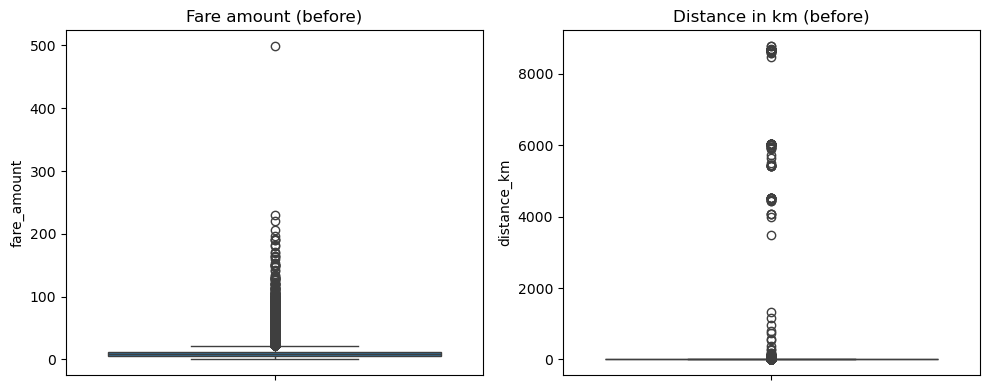

fare_amount : limits = (-3.75, 22.25),  outliers = 16619
distance_km : limits = (-2.74, 7.98),  outliers = 16321
Shape after removing outliers : (169019, 13)


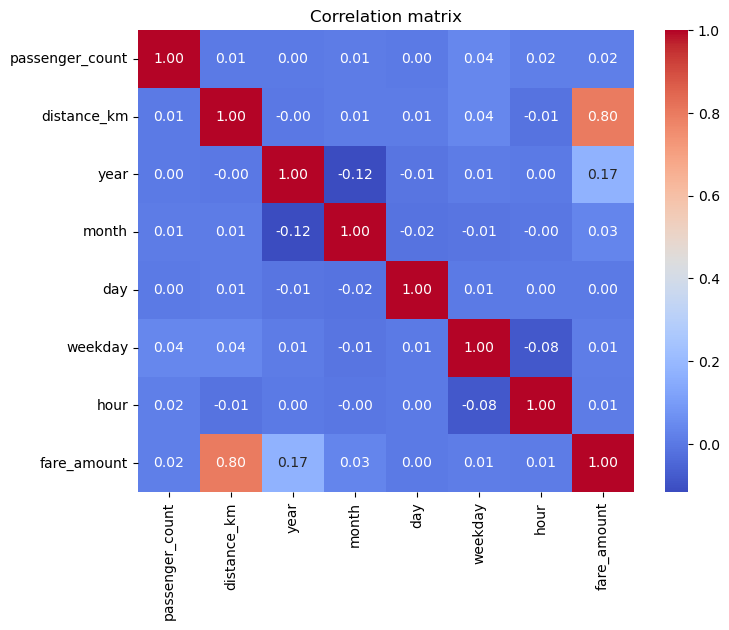


Correlation of each feature with fare_amount:
 distance_km        0.795531
year               0.173208
month              0.032687
passenger_count    0.016702
weekday            0.013184
hour               0.006767
day                0.004776
Name: fare_amount, dtype: float64

Model comparison:
                    Train R2  Test R2    RMSE     MAE
Model                                               
Linear Regression    0.6656   0.6708  2.1339  1.5250
Ridge Regression     0.6656   0.6708  2.1339  1.5250
Lasso Regression     0.6655   0.6708  2.1340  1.5256

Coefficients of the models:
                  Linear Regression  Ridge Regression  Lasso Regression
passenger_count             0.0439            0.0439            0.0339
distance_km                 2.9649            2.9649            2.9545
year                        0.6765            0.6765            0.6651
month                       0.1806            0.1806            0.1693
day                         0.0072            0.0072

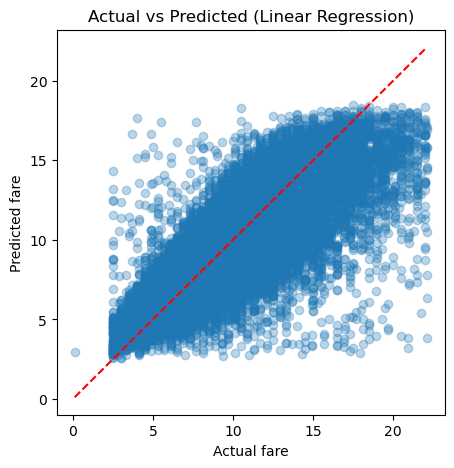


Predicted fare for a 5 km ride : $ 15.4


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
 
# ---------------- 1. Load the dataset ----------------
df = pd.read_csv('uber.csv')            # keep uber.csv in the same folder
print("Shape :", df.shape)
print(df.head())
df.info()
print("\nMissing values:\n", df.isnull().sum())
 
# ---------------- 2. Pre-process the dataset ----------------
# 2a. remove columns that are not useful for prediction
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
 
# 2b. remove rows with missing values
df = df.dropna()
 
# 2c. convert pickup_datetime to date-time and extract useful features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
df = df.dropna(subset=['pickup_datetime'])
df['year']    = df['pickup_datetime'].dt.year
df['month']   = df['pickup_datetime'].dt.month
df['day']     = df['pickup_datetime'].dt.day
df['weekday'] = df['pickup_datetime'].dt.weekday
df['hour']    = df['pickup_datetime'].dt.hour
 
# 2d. calculate the trip distance (km) with the Haversine formula
def haversine(lat1, lon1, lat2, lon2):
    R = 6371                                   # radius of earth in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))
 
df['distance_km'] = haversine(df['pickup_latitude'], df['pickup_longitude'],
                              df['dropoff_latitude'], df['dropoff_longitude'])
 
# 2e. remove impossible / invalid records
df = df[(df['fare_amount'] > 0) &
        (df['passenger_count'].between(1, 6)) &
        (df['pickup_latitude'].between(-90, 90)) & (df['dropoff_latitude'].between(-90, 90)) &
        (df['pickup_longitude'].between(-180, 180)) & (df['dropoff_longitude'].between(-180, 180)) &
        (df['distance_km'] > 0)]
print("\nShape after cleaning :", df.shape)
 
# ---------------- 3. Identify outliers ----------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df['fare_amount'], ax=ax[0]);  ax[0].set_title('Fare amount (before)')
sns.boxplot(y=df['distance_km'], ax=ax[1]);  ax[1].set_title('Distance in km (before)')
plt.tight_layout(); plt.show()
 
def iqr_limits(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
 
for col in ['fare_amount', 'distance_km']:
    low, high = iqr_limits(df[col])
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:12s}: limits = ({low:.2f}, {high:.2f}),  outliers = {n_out}")
 
# remove the outliers using the IQR rule
for col in ['fare_amount', 'distance_km']:
    low, high = iqr_limits(df[col])
    df = df[(df[col] >= low) & (df[col] <= high)]
print("Shape after removing outliers :", df.shape)
 
# ---------------- 4. Check the correlation ----------------
features = ['passenger_count', 'distance_km', 'year', 'month', 'day', 'weekday', 'hour']
corr = df[features + ['fare_amount']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix'); plt.show()
print("\nCorrelation of each feature with fare_amount:\n",
      corr['fare_amount'].drop('fare_amount').sort_values(ascending=False))
 
# ---------------- 5. Train / test split and scaling ----------------
X = df[features]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)      # fit only on training data
X_test_s  = scaler.transform(X_test)
 
# ---------------- 6. Linear, Ridge and Lasso regression ----------------
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression' : Ridge(alpha=1.0),
    'Lasso Regression' : Lasso(alpha=0.01),
}
results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred_tr, pred_te = model.predict(X_train_s), model.predict(X_test_s)
    results.append({
        'Model'     : name,
        'Train R2'  : r2_score(y_train, pred_tr),
        'Test R2'   : r2_score(y_test, pred_te),
        'RMSE'      : np.sqrt(mean_squared_error(y_test, pred_te)),
        'MAE'       : mean_absolute_error(y_test, pred_te),
    })
 
# ---------------- 7. Evaluate and compare the models ----------------
results_df = pd.DataFrame(results).set_index('Model').round(4)
print("\nModel comparison:\n", results_df)
 
coef_df = pd.DataFrame({name: m.coef_ for name, m in models.items()}, index=features).round(4)
print("\nCoefficients of the models:\n", coef_df)
 
best = results_df['Test R2'].idxmax()
print("\nBest model on test data :", best)
 
# actual vs predicted plot for the best model
pred = models[best].predict(X_test_s)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual fare'); plt.ylabel('Predicted fare'); plt.title(f'Actual vs Predicted ({best})')
plt.show()
 
# predict the price of a new ride (example)
new_ride = pd.DataFrame([[1, 5.0, 2015, 6, 15, 2, 18]], columns=features)   # 1 passenger, 5 km, 6 pm
print("\nPredicted fare for a 5 km ride : $", round(models[best].predict(scaler.transform(new_ride))[0], 2))